# 手語 Keypoint → 中文句子 Transformer

依序執行即可：
1. **設定**：路徑與參數
2. **建立資料集**：切分 train / val / test，建立字元表與標準化參數（資料有變動時才需要重跑）
3. **資料與模型定義**
4. **訓練**：存下驗證集 CER 最低的 `best.pt`
5. **預測與評估**：翻譯測試集並計算 CER

> 路徑是相對路徑，Jupyter 的工作目錄要是 `Data Preparation` 的上一層。
> 若 notebook 放在別的位置，先在第一格把 `os.chdir(...)` 改成那個資料夾。

## 1. 設定

In [12]:
import csv
import json
import math
import os
import random
import warnings
from pathlib import Path

import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
# os.chdir(r"C:\你的專案資料夾")   # Data Preparation 的上一層

# ================================================================ 路徑設定
LABEL_DIR = Path(r"..\Data Preparation\Phase5-Pause\output\03labels")
SEG_DIR = Path(r"..\Data Preparation\Phase5-Pause\output\03segments")
DATA_DIR = Path(r"data")
CKPT_DIR = Path(r"checkpoints")
PRED_DIR = Path(r"predictions")

# ================================================================ 資料集切分
SPLIT = (0.8, 0.1, 0.1)    # train / val / test (以子資料夾 = 原始影片為單位)
SEED = 42
SPECIALS = ["<pad>", "<bos>", "<eos>", "<unk>"]
FLAG_DIMS = [126, 127, 155]   # 存在旗標，不做標準化
MIN_FREQ = 3               # 訓練集中出現少於幾次的字當作 <unk>

# ================================================================ 資料設定
FRAME_STRIDE = 2           # 每幾幀取 1 幀
MAX_FRAMES = 300           # 取樣後最多幾幀
MAX_TEXT_LEN = 64          # 含 <bos> <eos> 最多幾個字
SPEED_RANGE = (0.8, 1.2)   # 訓練時隨機變速
NOISE_STD = 0.05           # 訓練時加的雜訊

# ================================================================ 模型設定
D_MODEL = 256
N_HEADS = 4
ENC_LAYERS = 4
DEC_LAYERS = 3
FF_DIM = 1024
DROPOUT = 0.2

# ================================================================ 訓練設定
BATCH_SIZE = 32
EPOCHS = 150
LR = 3e-4
WEIGHT_DECAY = 0.01
WARMUP_EPOCHS = 5
LABEL_SMOOTHING = 0.1
PATIENCE = 20              # 驗證集 CER 連續幾個 epoch 沒進步就停止

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"
PAD, BOS, EOS, UNK = 0, 1, 2, 3
print("device:", DEVICE)

device: cuda


## 2. 建立資料集
讀取所有 part 的 `03labels`、`03segments`，以子資料夾為單位切分，輸出到 `DATA_DIR`：
`train.csv` / `val.csv` / `test.csv`、`vocab.json`（只用訓練集的字）、`norm.npz`（訓練集每一維的平均 / 標準差）。

In [13]:
# {"<part>/<子資料夾>": [(分段路徑, 文字), ...]}
groups = {}
for txt in sorted(LABEL_DIR.glob("*/*/*.txt")):
    group = txt.parent.relative_to(LABEL_DIR)
    for line in txt.read_text(encoding="utf-8").splitlines():
        name, _, text = line.partition(": ")
        if text.strip():
            groups.setdefault(group.as_posix(), []).append(((group / f"{name}.npy").as_posix(), text.strip()))

keys = sorted(groups)
random.Random(SEED).shuffle(keys)
n_train, n_val = round(len(keys) * SPLIT[0]), round(len(keys) * SPLIT[1])
splits = {"train": keys[:n_train], "val": keys[n_train:n_train + n_val], "test": keys[n_train + n_val:]}

DATA_DIR.mkdir(parents=True, exist_ok=True)
rows = {}
for split, split_keys in splits.items():
    rows[split] = [row for key in sorted(split_keys) for row in groups[key]]
    with (DATA_DIR / f"{split}.csv").open("w", newline="", encoding="utf-8-sig") as f:
        writer = csv.writer(f)
        writer.writerow(("path", "text"))
        writer.writerows(rows[split])

from collections import Counter

freq = Counter(c for _, text in rows["train"] for c in text)
chars = sorted(c for c, n in freq.items() if n >= MIN_FREQ)
coverage = sum(freq[c] for c in chars) / sum(freq.values())
print(f"出現 {MIN_FREQ} 次以上的字：{len(chars)} / {len(freq)} 個，涵蓋訓練集 {coverage:.1%} 的字")
(DATA_DIR / "vocab.json").write_text(json.dumps(SPECIALS + chars, ensure_ascii=False), encoding="utf-8")

total, total_sq, count = np.zeros(156), np.zeros(156), 0
for path, _ in tqdm(rows["train"], desc="norm"):
    arr = np.load(SEG_DIR / path).astype(np.float64)
    total += arr.sum(0)
    total_sq += (arr ** 2).sum(0)
    count += len(arr)
mean = total / count
std = np.sqrt(np.maximum(total_sq / count - mean ** 2, 0)) + 1e-6
mean[FLAG_DIMS], std[FLAG_DIMS] = 0.0, 1.0
np.savez(DATA_DIR / "norm.npz", mean=mean.astype(np.float32), std=std.astype(np.float32))

for split in splits:
    print(f"{split}: {len(rows[split])} 句 ({len(splits[split])} 支影片)")
print(f"字元數: {len(chars)}")

出現 3 次以上的字：1542 / 2270 個，涵蓋訓練集 97.9% 的字


norm:   0%|          | 0/3894 [00:00<?, ?it/s]

train: 3894 句 (46 支影片)
val: 524 句 (6 支影片)
test: 390 句 (5 支影片)
字元數: 1542


## 3. 資料與模型定義

In [14]:
def load_vocab():
    return json.loads((DATA_DIR / "vocab.json").read_text(encoding="utf-8"))


class SignDataset(Dataset):
    def __init__(self, split, vocab, train=False):
        with (DATA_DIR / f"{split}.csv").open(encoding="utf-8-sig", newline="") as f:
            self.rows = [(row["path"], row["text"]) for row in csv.DictReader(f)]
        self.stoi = {c: i for i, c in enumerate(vocab)}
        norm = np.load(DATA_DIR / "norm.npz")
        self.mean, self.std = norm["mean"], norm["std"]
        self.train = train

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        path, text = self.rows[i]
        x = ((np.load(SEG_DIR / path).astype(np.float32) - self.mean) / self.std)[::FRAME_STRIDE]
        if self.train:
            n = max(1, round(len(x) * random.uniform(*SPEED_RANGE)))
            x = x[np.linspace(0, len(x) - 1, n).round().astype(int)]
            x = x + np.random.normal(0, NOISE_STD, x.shape).astype(np.float32)
        x = x[:MAX_FRAMES]
        ids = [BOS] + [self.stoi.get(c, UNK) for c in text[:MAX_TEXT_LEN - 2]] + [EOS]
        return torch.from_numpy(np.ascontiguousarray(x)), torch.tensor(ids)


def collate(batch):
    xs, ys = zip(*batch)
    src = nn.utils.rnn.pad_sequence(xs, batch_first=True)
    lengths = torch.tensor([len(x) for x in xs])
    src_mask = torch.arange(src.size(1))[None, :] >= lengths[:, None]     # True = padding
    tgt = nn.utils.rnn.pad_sequence(ys, batch_first=True, padding_value=PAD)
    return src, src_mask, tgt

In [15]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=2000):
        super().__init__()
        pos = torch.arange(max_len).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe)

    def forward(self, x):
        return x + self.pe[:x.size(1)]


class SignTransformer(nn.Module):
    def __init__(self, vocab_size, feat_dim=156):
        super().__init__()
        self.src_proj = nn.Sequential(
            nn.Linear(feat_dim, D_MODEL), nn.LayerNorm(D_MODEL), nn.GELU(),
            nn.Dropout(DROPOUT), nn.Linear(D_MODEL, D_MODEL),
        )
        self.tgt_emb = nn.Embedding(vocab_size, D_MODEL, padding_idx=PAD)
        self.pos = PositionalEncoding(D_MODEL)
        self.transformer = nn.Transformer(
            D_MODEL, N_HEADS, ENC_LAYERS, DEC_LAYERS, FF_DIM, DROPOUT,
            batch_first=True, norm_first=True,
        )
        self.out = nn.Linear(D_MODEL, vocab_size)

    def encode(self, src, src_mask):
        return self.transformer.encoder(self.pos(self.src_proj(src)), src_key_padding_mask=src_mask)

    def decode(self, tgt, memory, src_mask):
        L = tgt.size(1)
        causal = torch.triu(torch.ones(L, L, dtype=torch.bool, device=tgt.device), 1)
        h = self.transformer.decoder(
            self.pos(self.tgt_emb(tgt) * math.sqrt(D_MODEL)), memory,
            tgt_mask=causal, tgt_key_padding_mask=tgt == PAD, memory_key_padding_mask=src_mask,
        )
        return self.out(h)

    def forward(self, src, src_mask, tgt_in):
        return self.decode(tgt_in, self.encode(src, src_mask), src_mask)

In [16]:
@torch.no_grad()
def greedy_decode(model, src, src_mask):
    memory = model.encode(src, src_mask)
    ys = torch.full((src.size(0), 1), BOS, dtype=torch.long, device=src.device)
    done = torch.zeros(src.size(0), dtype=torch.bool, device=src.device)
    for _ in range(MAX_TEXT_LEN - 1):
        next_tok = model.decode(ys, memory, src_mask)[:, -1].argmax(-1)
        next_tok[done] = PAD
        ys = torch.cat([ys, next_tok[:, None]], dim=1)
        done |= next_tok == EOS
        if done.all():
            break
    return ys[:, 1:].tolist()


def ids_to_text(ids, vocab):
    chars = []
    for i in ids:
        if i in (EOS, PAD):
            break
        chars.append("□" if i == UNK else vocab[i])
    return "".join(chars)


def edit_distance(a, b):
    row = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        prev, row[0] = row[0], i
        for j, cb in enumerate(b, 1):
            prev, row[j] = row[j], min(row[j] + 1, row[j - 1] + 1, prev + (ca != cb))
    return row[-1]


def char_error_rate(preds, refs):
    """字元錯誤率：編輯距離總和 ÷ 正確答案總字數，越低越好。"""
    return sum(edit_distance(p, r) for p, r in zip(preds, refs)) / max(1, sum(len(r) for r in refs))


def predict_loader(model, loader, vocab, desc="decode"):
    model.eval()
    preds = []
    for src, src_mask, _ in tqdm(loader, desc=desc, leave=False):
        with torch.autocast(DEVICE, enabled=USE_AMP):
            out = greedy_decode(model, src.to(DEVICE), src_mask.to(DEVICE))
        preds += [ids_to_text(ids, vocab) for ids in out]
    return preds

## 4. 訓練
每個 epoch 顯示 train / val loss 與驗證集 CER；CER 最低的模型存成 `best.pt`。

In [17]:
def run_epoch(model, loader, criterion, optimizer=None, scheduler=None, scaler=None):
    train = optimizer is not None
    model.train(train)
    total, count = 0.0, 0
    for src, src_mask, tgt in tqdm(loader, desc="train" if train else "val", leave=False):
        src, src_mask, tgt = src.to(DEVICE), src_mask.to(DEVICE), tgt.to(DEVICE)
        with torch.set_grad_enabled(train), torch.autocast(DEVICE, enabled=USE_AMP):
            logits = model(src, src_mask, tgt[:, :-1])
            loss = criterion(logits.reshape(-1, logits.size(-1)), tgt[:, 1:].reshape(-1))
        if train:
            optimizer.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
        n = (tgt[:, 1:] != PAD).sum().item()
        total += loss.item() * n
        count += n
    return total / count


random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

vocab = load_vocab()
train_set = SignDataset("train", vocab, train=True)
val_set = SignDataset("val", vocab)
train_loader = DataLoader(train_set, BATCH_SIZE, shuffle=True, collate_fn=collate)
val_loader = DataLoader(val_set, BATCH_SIZE, collate_fn=collate)
val_refs = [text for _, text in val_set.rows]

model = SignTransformer(len(vocab)).to(DEVICE)
criterion = nn.CrossEntropyLoss(ignore_index=PAD, label_smoothing=LABEL_SMOOTHING)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
total_steps, warmup = EPOCHS * len(train_loader), WARMUP_EPOCHS * len(train_loader)
scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lambda step: step / warmup if step < warmup
    else 0.5 * (1 + math.cos(math.pi * (step - warmup) / max(1, total_steps - warmup))),
)
scaler = torch.amp.GradScaler(enabled=USE_AMP)

CKPT_DIR.mkdir(parents=True, exist_ok=True)
history = []
best_cer, stale = float("inf"), 0
bar = tqdm(range(1, EPOCHS + 1), desc="epoch")
for epoch in bar:
    train_loss = run_epoch(model, train_loader, criterion, optimizer, scheduler, scaler)
    with torch.no_grad():
        val_loss = run_epoch(model, val_loader, criterion)
    val_cer = char_error_rate(predict_loader(model, val_loader, vocab), val_refs)
    history.append((train_loss, val_loss, val_cer))

    torch.save(model.state_dict(), CKPT_DIR / "last.pt")
    if val_cer < best_cer:
        best_cer, stale = val_cer, 0
        torch.save(model.state_dict(), CKPT_DIR / "best.pt")
    else:
        stale += 1
    bar.set_postfix(train=f"{train_loss:.3f}", val=f"{val_loss:.3f}", cer=f"{val_cer:.3f}", best=f"{best_cer:.3f}")
    if stale >= PATIENCE:
        break

epoch:   0%|          | 0/150 [00:00<?, ?it/s]

train:   0%|          | 0/122 [00:00<?, ?it/s]

val:   0%|          | 0/17 [00:00<?, ?it/s]

decode:   0%|          | 0/17 [00:00<?, ?it/s]

train:   0%|          | 0/122 [00:00<?, ?it/s]

val:   0%|          | 0/17 [00:00<?, ?it/s]

... (66 outputs left out)

decode:   0%|          | 0/17 [00:00<?, ?it/s]

train:   0%|          | 0/122 [00:00<?, ?it/s]

val:   0%|          | 0/17 [00:00<?, ?it/s]

decode:   0%|          | 0/17 [00:00<?, ?it/s]

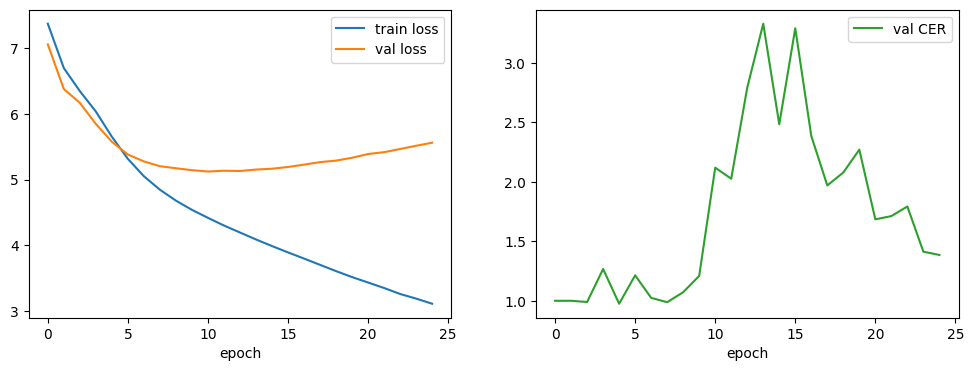

In [18]:
# 訓練曲線
import matplotlib.pyplot as plt

h = np.array(history)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(h[:, 0], label="train loss")
ax1.plot(h[:, 1], label="val loss")
ax1.set_xlabel("epoch")
ax1.legend()
ax2.plot(h[:, 2], label="val CER", color="C2")
ax2.set_xlabel("epoch")
ax2.legend()
plt.show()

## 5. 預測與評估
用 `best.pt` 翻譯 `PRED_SPLIT`，結果寫入 `PRED_DIR`，並顯示前幾句對照。

In [20]:
PRED_SPLIT = "test"    # train / val / test

vocab = load_vocab()
dataset = SignDataset(PRED_SPLIT, vocab)
loader = DataLoader(dataset, BATCH_SIZE, collate_fn=collate)

model = SignTransformer(len(vocab)).to(DEVICE)
model.load_state_dict(torch.load(CKPT_DIR / "best.pt", map_location=DEVICE))
preds = predict_loader(model, loader, vocab, desc=PRED_SPLIT)
refs = [text for _, text in dataset.rows]

PRED_DIR.mkdir(parents=True, exist_ok=True)
with (PRED_DIR / f"{PRED_SPLIT}_predictions.csv").open("w", newline="", encoding="utf-8-sig") as f:
    writer = csv.writer(f)
    writer.writerow(("path", "target", "prediction"))
    writer.writerows((path, ref, pred) for (path, _), ref, pred in zip(dataset.rows, refs, preds))

print(f"{PRED_SPLIT} CER = {char_error_rate(preds, refs):.3f}\n")
for (path, _), ref, pred in list(zip(dataset.rows, refs, preds))[:10]:
    print(f"{path}\n  答案：{ref}\n  預測：{pred}")

test:   0%|          | 0/13 [00:00<?, ?it/s]

test CER = 0.976

1/2/000650_001590_s00.npy
  答案：今天初六開工日
  預測：台灣有10萬元
1/2/000650_001590_s01.npy
  答案：不過天氣變得又濕又冷
  預測：台灣有10萬元
1/2/000650_001590_s02.npy
  答案：受到強烈大陸冷氣團南下
  預測：台灣有10萬元
1/2/000650_001590_s03.npy
  答案：和華南雲雨區東移的影響
  預測：台灣有10萬元
1/2/000650_001590_s04.npy
  答案：各地氣溫明顯下降 降雨機率也提高
  預測：台灣有10萬元
1/2/000650_001590_s05.npy
  答案：尤其在北台灣越晚會越冷
  預測：台灣有10萬元
1/2/000650_001590_s06.npy
  答案：氣溫會降到10到12度
  預測：台灣有10萬元
1/2/000650_001590_s07.npy
  答案：而這樣濕冷的天氣將會一路持續到星期三
  預測：台灣有10萬元
1/2/005066_006141_s00.npy
  答案：春節期間不少人上吐下瀉送醫
  預測：台灣有10萬元
1/2/005066_006141_s01.npy
  答案：台大醫院還一度通報急診滿床
  預測：台灣有10萬元
